# 06. Đánh giá mô hình chính M1 và bộ hình dùng chung cho paper, slide

Notebook này **không huấn luyện mô hình mới**. Nó chạy lại đúng thiết kế của notebook 03–05 (cùng 192 chuyến, cùng 50 cách chia, seed 301) để:

1. Mô tả đầy đủ M1 (hồi quy tuyến tính + speed²): hệ số, khoảng tin cậy, ví dụ tính năng lượng dự đoán.
2. Kiểm tra lựa chọn bậc của tốc độ (bậc 1, 2, 3) và thêm tương tác, bằng cùng cross-validation.
3. Vẽ **Actual vs Predicted** và **Residual plot** của M1.
4. Phân tích khi nào M1 tốt hơn hoặc kém hơn Gradient Boosting (theo nhóm, theo ngoại suy).
5. Phân tích sai số trên tuyến R6 và ảnh hưởng của việc không dùng cự ly (Distance).
6. Mô tả cách tính q90 của lớp quyết định.
7. Xuất **một bộ hình duy nhất** (`reports/figures/final_*.png`) dùng cho cả paper và slide, để số liệu, nhãn và cách vẽ thống nhất.

Cần `data/raw/flights.csv` (cột flight, time, position_x, position_y) cho phần cự ly, giống notebook 03.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import RepeatedKFold, KFold, GridSearchCV, cross_val_predict

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "reports" / "figures"
SEED = 301

# Một phong cách cho mọi hình final (paper và slide dùng chung file)
MAU = {"M1": "#E07B24", "base": "#9AA5B1", "cmp": "#2F5D8A", "cmp2": "#1B3550", "R6": "#C0392B", "R1": "#2F5D8A"}
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
                     "axes.spines.top": False, "axes.spines.right": False, "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.pad_inches": 0.03,
                     "legend.fontsize": 8, "legend.frameon": False})
KQ = {}   # các con số dùng trong paper, lưu ra reports/final_numbers.json

In [2]:
df = pd.read_csv(PROCESSED / "flight_level.csv")
FEATURE = ["speed", "payload", "altitude"]
X, y = df[FEATURE], df["E_Wh"]

# Cự ly tuyến: giống notebook 03 (trung vị quãng đường GPS của mỗi tuyến)
gps = pd.read_csv(RAW / "flights.csv", usecols=["flight", "time", "position_x", "position_y"])
gps = gps[gps["flight"].isin(df["flight"])].sort_values(["flight", "time"])
R = 6_371_000
lat0 = np.radians(gps["position_y"].mean())
gps["x_m"] = np.radians(gps["position_x"]) * R * np.cos(lat0)
gps["y_m"] = np.radians(gps["position_y"]) * R
gps["doan_m"] = np.hypot(gps.groupby("flight")["x_m"].diff(), gps.groupby("flight")["y_m"].diff())
df = df.join(gps.groupby("flight")["doan_m"].sum().rename("quang_duong_do_m"), on="flight")
df["cu_ly_m"] = df.groupby("route")["quang_duong_do_m"].transform("median")
nhom_tuyen = np.where(df["route"] == "R6", "R6", "R1–R5")
print(df.groupby("route")["cu_ly_m"].first().round(0).to_dict())
print(pd.Series(nhom_tuyen).value_counts().to_dict())

{'R1': 472.0, 'R2': 427.0, 'R3': 467.0, 'R4': 475.0, 'R5': 534.0, 'R6': 837.0}
{'R1–R5': 187, 'R6': 5}


## 1. Hình EDA dùng chung (chấm từng chuyến + đường trung bình, có ghi giá trị trung bình)

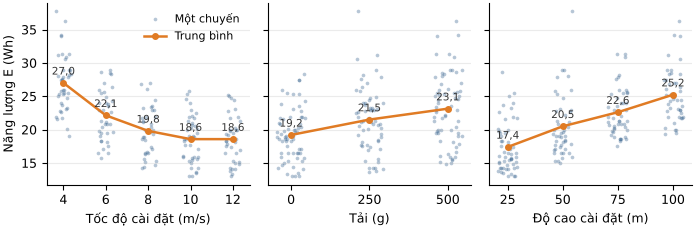

{'speed': {'4': 27.0, '6': 22.1, '8': 19.8, '10': 18.6, '12': 18.6},
 'payload': {'0': 19.2, '250': 21.5, '500': 23.1},
 'altitude': {'25': 17.4, '50': 20.5, '75': 22.6, '100': 25.2}}

In [3]:
TEN = {"speed": "Tốc độ cài đặt (m/s)", "payload": "Tải (g)", "altitude": "Độ cao cài đặt (m)"}
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(1, 3, figsize=(7.16, 2.5), sharey=True)
TB_EDA = {}
for ax, cot in zip(axes, FEATURE):
    muc = sorted(df[cot].unique())
    vi_tri = df[cot].map({m: i for i, m in enumerate(muc)})
    ax.scatter(vi_tri + rng.uniform(-0.18, 0.18, len(df)), y, s=7, alpha=0.35, color=MAU["cmp"], lw=0,
               label="Một chuyến")
    tb = df.groupby(cot)["E_Wh"].mean()
    TB_EDA[cot] = {str(int(k)): round(v, 1) for k, v in tb.items()}
    ax.plot(range(len(muc)), tb.values, color=MAU["M1"], marker="o", ms=4, lw=1.8, label="Trung bình")
    for i, v in enumerate(tb.values):
        ax.annotate(f"{v:.1f}".replace(".", ","), (i, v), textcoords="offset points", xytext=(0, 6),
                    ha="center", fontsize=7.5, color="#333")
    ax.set_xticks(range(len(muc)))
    ax.set_xticklabels([int(m) for m in muc])
    ax.set_xlabel(TEN[cot])
    ax.grid(axis="y", alpha=0.25)
axes[0].set_ylabel("Năng lượng E (Wh)")
axes[0].legend(loc="upper right")
plt.tight_layout()
plt.savefig(FIGURES / "final_eda.png")
plt.show()
KQ["eda_mean"] = TB_EDA
TB_EDA

## 2. Mô hình chính M1: hệ số trên toàn bộ 192 chuyến

In [4]:
def them_speed2(X):
    X = np.asarray(X, dtype=float)
    return np.column_stack([X, X[:, 0] ** 2])

A = np.column_stack([np.ones(len(df)), df["speed"], df["speed"] ** 2, df["payload"], df["altitude"]])
beta, *_ = np.linalg.lstsq(A, y, rcond=None)
res = y - A @ beta
n, k = A.shape
s2 = res @ res / (n - k)
se = np.sqrt(np.diag(s2 * np.linalg.inv(A.T @ A)))
tcrit = stats.t.ppf(0.975, n - k)
he_so = pd.DataFrame({"beta": beta, "se": se, "ci_lo": beta - tcrit * se, "ci_hi": beta + tcrit * se,
                      "p": 2 * stats.t.sf(np.abs(beta / se), n - k)},
                     index=["b0 (hằng số)", "b1 (v)", "b2 (v²)", "b3 (m, mỗi g)", "b4 (h, mỗi m)"])
r2_train = 1 - (res @ res) / ((y - y.mean()) @ (y - y.mean()))
v_min = -beta[1] / (2 * beta[2])
print(f"R² trên toàn bộ dữ liệu (train) = {r2_train:.3f}; sigma phần dư = {np.sqrt(s2):.2f} Wh; v* = {v_min:.2f} m/s")
KQ["m1_coef"] = he_so.round(5).to_dict(orient="index")
KQ["m1_r2_full"] = round(r2_train, 4)
KQ["m1_sigma"] = round(float(np.sqrt(s2)), 3)
KQ["m1_vstar"] = round(float(v_min), 2)
he_so.round(5)

R² trên toàn bộ dữ liệu (train) = 0.913; sigma phần dư = 1.46 Wh; v* = 10.65 m/s


,beta,se,ci_lo,ci_hi,p
b0 (hằng số),32.19602,0.96561,30.29114,34.10090,0.0
b1 (v),-4.19437,0.25542,-4.69825,-3.69050,0.0
b2 (v²),0.19687,0.01587,0.16556,0.22817,0.0
"b3 (m, mỗi g)",0.00810,0.00051,0.00709,0.00911,0.0
"b4 (h, mỗi m)",0.10496,0.00375,0.09756,0.11236,0.0


In [5]:
# Ví dụ tính năng lượng dự đoán cho một chuyến cụ thể
def du_doan_m1(v, m, h):
    return beta[0] + beta[1] * v + beta[2] * v ** 2 + beta[3] * m + beta[4] * h

vi_du = {(8, 250, 50): None, (4, 500, 100): None, (10, 0, 25): None}
for key in vi_du:
    vi_du[key] = round(float(du_doan_m1(*key)), 2)
    that = df[(df["speed"] == key[0]) & (df["payload"] == key[1]) & (df["altitude"] == key[2]) & (df["route"] == "R1")]["E_Wh"]
    print(key, "-> Ê =", vi_du[key], "Wh | đo thật trung bình (R1):", round(that.mean(), 2), "n =", len(that))
KQ["m1_examples"] = {f"{a}|{b}|{c}": v for (a, b, c), v in vi_du.items()}
# Tác động biên dễ đọc
KQ["m1_effects"] = {"payload_100g": round(beta[3] * 100, 2), "altitude_25m": round(beta[4] * 25, 2),
                    "speed_4_to_10": round(float(du_doan_m1(10, 0, 0) - du_doan_m1(4, 0, 0)), 2),
                    "speed_10_to_12": round(float(du_doan_m1(12, 0, 0) - du_doan_m1(10, 0, 0)), 2)}
KQ["m1_effects"]

(8, 250, 50) -> Ê = 18.51 Wh | đo thật trung bình (R1): 18.88 n = 3
(4, 500, 100) -> Ê = 33.11 Wh | đo thật trung bình (R1): 34.81 n = 3
(10, 0, 25) -> Ê = 12.56 Wh | đo thật trung bình (R1): 13.21 n = 3


{'payload_100g': np.float64(0.81),
 'altitude_25m': np.float64(2.62),
 'speed_4_to_10': -8.63,
 'speed_10_to_12': 0.27}

## 3. Cross-validation chung cho mọi mô hình (giống notebook 03, 04) + chọn bậc của tốc độ

In [6]:
cv = RepeatedKFold(n_splits=5, n_repeats=10, random_state=SEED)
CHIA = list(cv.split(X))
cv_trong = KFold(n_splits=5, shuffle=True, random_state=SEED)

def poly_speed(bac, tuong_tac=False):
    def f(X):
        X = np.asarray(X, dtype=float)
        cot = [X] + [X[:, [0]] ** b for b in range(2, bac + 1)]
        if tuong_tac:
            cot += [X[:, [0]] * X[:, [1]], X[:, [0]] * X[:, [2]], X[:, [1]] * X[:, [2]]]
        return np.column_stack(cot)
    return make_pipeline(FunctionTransformer(f), LinearRegression())

MO_HINH = {   # tên: (mô hình, cột đầu vào, vai trò)
    "B0": (DummyRegressor(), FEATURE, "Baseline"),
    "B1": (LinearRegression(), ["cu_ly_m"], "Baseline"),
    "B2": (LinearRegression(), FEATURE, "Baseline"),
    "B3": (Ridge(alpha=1.0), FEATURE, "Baseline"),
    "M1": (poly_speed(2), FEATURE, "Chính"),
    "M2": (GridSearchCV(RandomForestRegressor(n_estimators=200, random_state=SEED), {"min_samples_leaf": [1, 3, 5]},
                        cv=cv_trong, scoring="neg_mean_absolute_error", n_jobs=-1), FEATURE, "So sánh"),
    "M3": (GridSearchCV(GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, random_state=SEED),
                        {"max_depth": [1, 2, 3]}, cv=cv_trong, scoring="neg_mean_absolute_error", n_jobs=-1),
           FEATURE, "So sánh"),
    # Kiểm tra lựa chọn dạng hàm của M1 (không phải mô hình được báo cáo chính)
    "M1-bậc3": (poly_speed(3), FEATURE, "Kiểm tra"),
    "M1+tương tác": (poly_speed(2, True), FEATURE, "Kiểm tra"),
    # Thăm dò vai trò của cự ly
    "B2+cự ly": (LinearRegression(), FEATURE + ["cu_ly_m"], "Thăm dò"),
    "M1+cự ly": (make_pipeline(FunctionTransformer(lambda Z: np.column_stack([np.asarray(Z, float), np.asarray(Z, float)[:, [0]] ** 2])), LinearRegression()),
                 FEATURE + ["cu_ly_m"], "Thăm dò"),
}

diem, oof = {}, {}
for ten, (m, cot, _) in MO_HINH.items():
    Xm = df[cot]
    mae, rmse, r2 = [], [], []
    tong, dem = np.zeros(len(y)), np.zeros(len(y))
    for tr, te in CHIA:
        p = clone(m).fit(Xm.iloc[tr], y.iloc[tr]).predict(Xm.iloc[te])
        e = y.iloc[te].to_numpy() - p
        mae.append(np.abs(e).mean()); rmse.append(np.sqrt((e ** 2).mean()))
        r2.append(1 - (e ** 2).sum() / ((y.iloc[te] - y.iloc[te].mean()) ** 2).sum())
        tong[te] += p; dem[te] += 1
    diem[ten] = {"MAE": np.array(mae), "RMSE": np.array(rmse), "R2": np.array(r2)}
    oof[ten] = tong / dem

bang = pd.DataFrame({t: {"vai_tro": MO_HINH[t][2],
                         "MAE": d["MAE"].mean(), "MAE_sd": d["MAE"].std(),
                         "RMSE": d["RMSE"].mean(), "RMSE_sd": d["RMSE"].std(),
                         "R2": d["R2"].mean(), "R2_sd": d["R2"].std()} for t, d in diem.items()}).T
bang.to_csv(ROOT / "reports" / "final_model_table.csv", encoding="utf-8-sig")
KQ["cv"] = {t: {k: (round(float(v), 4) if k != "vai_tro" else v) for k, v in r.items()} for t, r in bang.iterrows()}
bang

,vai_tro,MAE,MAE_sd,RMSE,RMSE_sd,R2,R2_sd
B0,Baseline,3.979067,0.431819,4.902997,0.522619,-0.057666,0.112074
B1,Baseline,4.007129,0.454262,4.945486,0.531561,-0.077186,0.12774
B2,Baseline,1.478173,0.167858,1.937441,0.461857,0.829075,0.071768
B3,Baseline,1.478087,0.167816,1.937373,0.462057,0.829091,0.071784
M1,Chính,0.849376,0.172275,1.375493,0.549327,0.907776,0.067123
M2,So sánh,0.881764,0.211775,1.536745,0.559293,0.884563,0.076906
M3,So sánh,0.832871,0.187492,1.408803,0.547852,0.903435,0.067276
M1-bậc3,Kiểm tra,0.821813,0.175862,1.357055,0.559175,0.909463,0.067838
M1+tương tác,Kiểm tra,0.742097,0.171093,1.316823,0.569995,0.913747,0.067337
B2+cự ly,Thăm dò,1.362143,0.106282,1.675139,0.206514,0.874249,0.030462


In [7]:
def t_hieu_chinh(a, b):
    d = diem[a]["MAE"] - diem[b]["MAE"]
    n_te, n_tr = len(CHIA[0][1]), len(CHIA[0][0])
    t = d.mean() / np.sqrt((1 / len(d) + n_te / n_tr) * d.var(ddof=1))
    return {"chenh": round(float(d.mean()), 3), "t": round(float(t), 2),
            "p": float(2 * stats.t.sf(abs(t), len(d) - 1)), "b_thang": int((d > 0).sum())}

cap = [("B2", "M1"), ("B2", "M2"), ("B2", "M3"), ("M1", "M3"), ("M1", "M2"), ("M1", "M1-bậc3"), ("M1", "M1+tương tác")]
KQ["ttest"] = {f"{a}-{b}": t_hieu_chinh(a, b) for a, b in cap}
pd.DataFrame(KQ["ttest"]).T

,chenh,t,p,b_thang
B2-M1,0.629,9.24,2.563385e-12,50.0
B2-M2,0.596,6.69,1.970925e-08,50.0
B2-M3,0.645,8.57,2.573729e-11,50.0
M1-M3,0.017,0.27,7.894427e-01,33.0
M1-M2,-0.032,-0.40,6.927196e-01,24.0
M1-M1-bậc3,0.028,1.57,1.219594e-01,43.0
M1-M1+tương tác,0.107,3.65,6.455159e-04,48.0


## 4. Biểu đồ so sánh MAE (M1 được tô nổi bật)

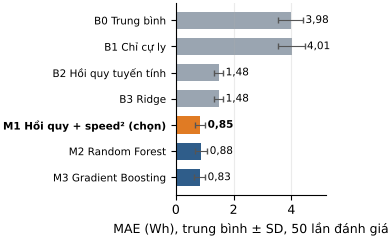

In [8]:
thu_tu = ["B0", "B1", "B2", "B3", "M1", "M2", "M3"]
nhan = {"B0": "B0 Trung bình", "B1": "B1 Chỉ cự ly", "B2": "B2 Hồi quy tuyến tính", "B3": "B3 Ridge",
        "M1": "M1 Hồi quy + speed² (chọn)", "M2": "M2 Random Forest", "M3": "M3 Gradient Boosting"}
mau = [MAU["base"]] * 4 + [MAU["M1"], MAU["cmp"], MAU["cmp"]]
fig, ax = plt.subplots(figsize=(3.5, 2.6))
gt = [bang.loc[t, "MAE"] for t in thu_tu]
sd = [bang.loc[t, "MAE_sd"] for t in thu_tu]
ax.barh(range(len(thu_tu)), gt, xerr=sd, color=mau, height=0.65, error_kw={"lw": 0.8, "capsize": 2, "ecolor": "#555"})
for i, (v, s) in enumerate(zip(gt, sd)):
    ax.text(v + s + 0.08, i, f"{v:.2f}".replace(".", ","), va="center", fontsize=7.5,
            fontweight="bold" if thu_tu[i] == "M1" else "normal")
ax.set_yticks(range(len(thu_tu)))
ax.set_yticklabels([nhan[t] for t in thu_tu], fontsize=7.5)
ax.get_yticklabels()[4].set_fontweight("bold")
ax.invert_yaxis()
ax.set_xlabel("MAE (Wh), trung bình ± SD, 50 lần đánh giá")
ax.set_xlim(0, 5.2)
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.savefig(FIGURES / "final_mae.png")
plt.show()

## 5. Actual vs Predicted và Residual plot của M1

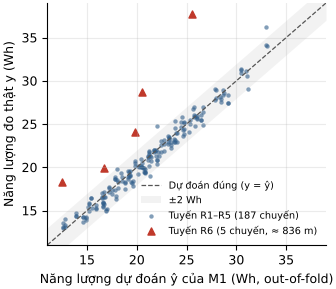

{'mae_all': 0.844,
 'mae_R1R5': 0.687,
 'mae_R6': 6.715,
 'within_2Wh_R1R5': 0.973,
 'within_2Wh_all': 0.948,
 'bias_R1R5': -0.181,
 'bias_R6': 6.715,
 'r6_under_pct': [39.4, 18.9, 21.4, 47.5, 47.5],
 'max_over': -2.27,
 'max_under': 12.16}

In [9]:
y_hat = oof["M1"]                # trung bình 10 dự đoán out-of-fold của mỗi chuyến
e_m1 = y - y_hat                 # > 0: đoán thiếu (thực tế tốn hơn dự đoán)
la_r6 = df["route"] == "R6"

fig, ax = plt.subplots(figsize=(3.5, 3.1))
lo, hi = 11, 39
ax.plot([lo, hi], [lo, hi], color="#555", lw=0.9, ls="--", label="Dự đoán đúng (y = ŷ)")
ax.fill_between([lo, hi], [lo - 2, hi - 2], [lo + 2, hi + 2], color="#999", alpha=0.12, lw=0, label="±2 Wh")
ax.scatter(y_hat[~la_r6], y[~la_r6], s=10, alpha=0.6, color=MAU["R1"], lw=0, label="Tuyến R1–R5 (187 chuyến)")
ax.scatter(y_hat[la_r6], y[la_r6], s=26, color=MAU["R6"], marker="^", label="Tuyến R6 (5 chuyến, ≈ 836 m)")
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
ax.set_xlabel("Năng lượng dự đoán ŷ của M1 (Wh, out-of-fold)")
ax.set_ylabel("Năng lượng đo thật y (Wh)")
ax.legend(loc="lower right", fontsize=7)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(FIGURES / "final_m1_actual_pred.png")
plt.show()

KQ["m1_oof"] = {"mae_all": round(float(np.abs(e_m1).mean()), 3),
                "mae_R1R5": round(float(np.abs(e_m1[~la_r6]).mean()), 3),
                "mae_R6": round(float(np.abs(e_m1[la_r6]).mean()), 3),
                "within_2Wh_R1R5": round(float((np.abs(e_m1[~la_r6]) <= 2).mean()), 3),
                "within_2Wh_all": round(float((np.abs(e_m1) <= 2).mean()), 3),
                "bias_R1R5": round(float(e_m1[~la_r6].mean()), 3),
                "bias_R6": round(float(e_m1[la_r6].mean()), 3),
                "r6_under_pct": [round(float(v), 1) for v in (e_m1[la_r6] / y_hat[la_r6] * 100)],
                "max_over": round(float(e_m1.min()), 2), "max_under": round(float(e_m1.max()), 2)}
KQ["m1_oof"]

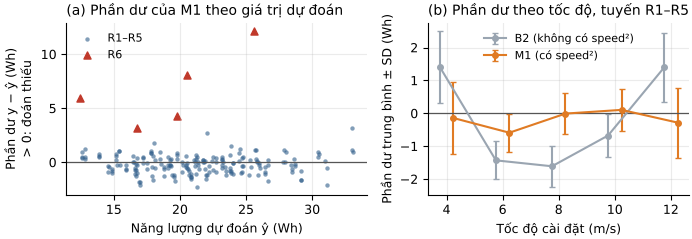

({'B2': {'4': 1.41, '6': -1.43, '8': -1.61, '10': -0.68, '12': 1.39},
  'M1': {'4': -0.14, '6': -0.59, '8': -0.01, '10': 0.1, '12': -0.28}},
 {'B2': 1.2785027656863185e-49, 'M1': 0.004484832251076424},
 [np.float64(0.005), np.float64(0.948)])

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(7.16, 2.6), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
ax.axhline(0, color="#555", lw=0.9)
ax.scatter(y_hat[~la_r6], e_m1[~la_r6], s=10, alpha=0.6, color=MAU["R1"], lw=0, label="R1–R5")
ax.scatter(y_hat[la_r6], e_m1[la_r6], s=26, color=MAU["R6"], marker="^", label="R6")
ax.set_xlabel("Năng lượng dự đoán ŷ (Wh)")
ax.set_ylabel("Phần dư y − ŷ (Wh)\n> 0: đoán thiếu")
ax.set_title("(a) Phần dư của M1 theo giá trị dự đoán", loc="left")
ax.legend(loc="upper left")
ax.grid(alpha=0.25)

ax = axes[1]
muc = sorted(df["speed"].unique())
e_b2 = y - oof["B2"]
for ten, e, mau_, dx in [("B2 (không có speed²)", e_b2, MAU["base"], -0.12), ("M1 (có speed²)", e_m1, MAU["M1"], 0.12)]:
    tb = e[~la_r6].groupby(df.loc[~la_r6, "speed"]).mean()
    sdv = e[~la_r6].groupby(df.loc[~la_r6, "speed"]).std()
    ax.errorbar(np.arange(len(muc)) + dx, tb.values, yerr=sdv.values, fmt="o-", color=mau_, ms=4, lw=1.5,
                capsize=2, label=ten)
ax.axhline(0, color="#555", lw=0.9)
ax.set_xticks(range(len(muc))); ax.set_xticklabels([int(m) for m in muc])
ax.set_xlabel("Tốc độ cài đặt (m/s)")
ax.set_ylabel("Phần dư trung bình ± SD (Wh)")
ax.set_title("(b) Phần dư theo tốc độ, tuyến R1–R5", loc="left")
ax.legend(loc="upper center")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(FIGURES / "final_m1_residuals.png")
plt.show()

KQ["resid_by_speed"] = {
    "B2": {str(int(k)): round(v, 2) for k, v in e_b2[~la_r6].groupby(df.loc[~la_r6, "speed"]).mean().items()},
    "M1": {str(int(k)): round(v, 2) for k, v in e_m1[~la_r6].groupby(df.loc[~la_r6, "speed"]).mean().items()},
}
# Phần dư có còn phụ thuộc tốc độ không? (ANOVA trên phần dư, R1–R5)
KQ["resid_anova_p"] = {t: float(stats.f_oneway(*[g.values for _, g in e[~la_r6].groupby(df.loc[~la_r6, "speed"])]).pvalue)
                       for t, e in [("B2", e_b2), ("M1", e_m1)]}
# Phương sai phần dư có tăng theo ŷ không (Spearman |e| vs ŷ, R1–R5)
KQ["resid_hetero_spearman"] = [round(v, 3) for v in stats.spearmanr(y_hat[~la_r6], np.abs(e_m1[~la_r6]))]
KQ["resid_by_speed"], KQ["resid_anova_p"], KQ["resid_hetero_spearman"]

## 6. Khi nào M1 tốt hơn, kém hơn Gradient Boosting

In [11]:
e_m3 = y - oof["M3"]
e_m2 = y - oof["M2"]
nhom = pd.DataFrame({"speed": df["speed"], "altitude": df["altitude"], "payload": df["payload"], "tuyen": nhom_tuyen,
                     "M1": np.abs(e_m1), "M2": np.abs(e_m2), "M3": np.abs(e_m3), "B2": np.abs(e_b2)})
theo = {}
for cot in ["speed", "altitude", "payload", "tuyen"]:
    g = nhom.groupby(cot)[["B2", "M1", "M2", "M3"]].mean().round(2)
    theo[cot] = g
    print(cot); print(g, "\n")
KQ["subgroup"] = {c: {str(k): r.to_dict() for k, r in g.iterrows()} for c, g in theo.items()}
KQ["m1_better_than_m3_flights"] = int((np.abs(e_m1) < np.abs(e_m3)).sum())
print("Số chuyến M1 sai ít hơn M3:", KQ["m1_better_than_m3_flights"], "/", len(df))

speed
         B2    M1    M2    M3
speed                        
4.0    1.79  1.13  1.27  1.24
6.0    1.58  0.85  0.95  0.87
8.0    1.61  0.49  0.40  0.41
10.0   0.91  0.77  0.71  0.65
12.0   1.52  0.95  0.81  0.80 

altitude
            B2    M1    M2    M3
altitude                        
25        1.68  1.09  1.10  0.99
50        1.54  0.81  0.93  0.92
75        1.41  0.70  0.64  0.62
100       1.23  0.74  0.63  0.65 

payload
           B2    M1    M2    M3
payload                        
0.0      1.30  0.81  0.71  0.65
250.0    1.48  0.77  0.91  0.87
500.0    1.65  0.95  0.89  0.88 

tuyen
         B2    M1    M2    M3
tuyen                        
R1–R5  1.33  0.69  0.67  0.64
R6     6.85  6.71  7.00  6.89 

Số chuyến M1 sai ít hơn M3: 86 / 192


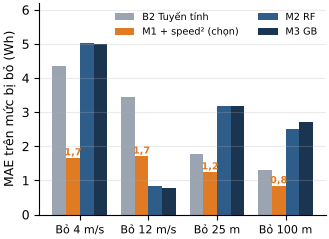

,B2,M1,M2,M3
speed=4,4.34,1.66,5.02,4.99
speed=12,3.43,1.71,0.85,0.78
altitude=25,1.76,1.25,3.19,3.20
altitude=100,1.31,0.84,2.50,2.72


In [12]:
# Ngoại suy: bỏ hẳn một mức khỏi tập train, đoán đúng mức đó (giống notebook 04)
CHINH = ["B2", "M1", "M2", "M3"]
ngoai_suy = {}
for cot, muc in [("speed", 4), ("speed", 12), ("altitude", 25), ("altitude", 100)]:
    tr = df[cot] != muc
    te = ~tr
    ngoai_suy[f"{cot}={muc}"] = {t: float(np.abs(y[te] - clone(MO_HINH[t][0]).fit(X[tr], y[tr]).predict(X[te])).mean())
                                 for t in CHINH}
ns = pd.DataFrame(ngoai_suy).T
KQ["extrap"] = ns.round(3).to_dict(orient="index")

nhan_ns = {"speed=4": "Bỏ 4 m/s", "speed=12": "Bỏ 12 m/s", "altitude=25": "Bỏ 25 m", "altitude=100": "Bỏ 100 m"}
mau_ns = {"B2": MAU["base"], "M1": MAU["M1"], "M2": MAU["cmp"], "M3": MAU["cmp2"]}
ten_ns = {"B2": "B2 Tuyến tính", "M1": "M1 + speed² (chọn)", "M2": "M2 RF", "M3": "M3 GB"}
fig, ax = plt.subplots(figsize=(3.5, 2.6))
w = 0.2
for j, t in enumerate(CHINH):
    ax.bar(np.arange(len(ns)) + (j - 1.5) * w, ns[t], w, color=mau_ns[t], label=ten_ns[t])
for i, v in enumerate(ns["M1"]):
    ax.text(i - 0.5 * w, v + 0.08, f"{v:.1f}".replace(".", ","), ha="center", fontsize=7, color=MAU["M1"], fontweight="bold")
ax.set_xticks(range(len(ns))); ax.set_xticklabels([nhan_ns[i] for i in ns.index], fontsize=8)
ax.set_ylabel("MAE trên mức bị bỏ (Wh)")
ax.legend(ncol=2, loc="upper right", fontsize=7)
ax.set_ylim(0, 6.2)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(FIGURES / "final_extrapolation.png")
plt.show()
ns.round(2)

## 7. Tuyến R6 và vai trò của cự ly

In [13]:
tuyen = pd.DataFrame({t: np.abs(y - oof[t]).groupby(nhom_tuyen).mean() for t in ["B2", "M1", "M2", "M3", "B2+cự ly", "M1+cự ly"]}).T.round(2)
tuyen["Toàn bộ"] = [round(float(bang.loc[t, "MAE"]), 3) for t in tuyen.index]
KQ["route_mae"] = tuyen.to_dict(orient="index")
r6 = df.loc[la_r6, ["flight", "speed", "payload", "altitude", "E_Wh"]].copy()
r6["M1_du_doan"] = y_hat[la_r6].round(1)
r6["M1_thieu_%"] = (e_m1[la_r6] / y_hat[la_r6] * 100).round(0)
r6["M1+cự ly"] = oof["M1+cự ly"][la_r6].round(1)
KQ["r6_table"] = r6.round(1).to_dict(orient="records")
KQ["route_len"] = {"R1": round(float(df.loc[df.route == "R1", "cu_ly_m"].iloc[0])), "R6": round(float(df.loc[la_r6, "cu_ly_m"].iloc[0]))}
print(tuyen); r6

          R1–R5    R6  Toàn bộ
B2         1.33  6.85    1.478
M1         0.69  6.71    0.849
M2         0.67  7.00    0.882
M3         0.64  6.89    0.833
B2+cự ly   1.30  3.50    1.362
M1+cự ly   0.64  3.36    0.713


,flight,speed,payload,altitude,E_Wh,M1_du_doan,M1_thieu_%,M1+cự ly
184,268,6.0,500.0,25,28.664513,20.6,39.0,26.4
185,269,12.0,500.0,25,19.914951,16.8,19.0,24.2
186,270,10.0,250.0,75,24.035845,19.8,21.0,26.8
187,271,10.0,0.0,25,18.352936,12.4,47.0,19.0
188,272,4.0,250.0,50,37.747051,25.6,48.0,30.9


## 8. q90 của lớp quyết định (giống notebook 05)

In [14]:
ngoai = KFold(n_splits=5, shuffle=True, random_state=SEED)
q_list, ty_so_all = [], np.zeros(len(df))
pred5 = np.zeros(len(df))
M1 = MO_HINH["M1"][0]
for tr, te in ngoai.split(X):
    trong = KFold(n_splits=5, shuffle=True, random_state=SEED)
    oof_tr = cross_val_predict(clone(M1), X.iloc[tr], y.iloc[tr], cv=trong)
    ty_so = y.iloc[tr] / oof_tr
    q_list.append(float(np.quantile(ty_so, 0.90)))
    pred5[te] = clone(M1).fit(X.iloc[tr], y.iloc[tr]).predict(X.iloc[te])
ty_so_all = y / pred5
KQ["q90"] = {"per_fold": [round(q, 3) for q in q_list], "mean": round(float(np.mean(q_list)), 3)}
# Độ phủ thật trên tập test: tỉ lệ chuyến có năng lượng đo ≤ cận trên
fold_of = np.zeros(len(df), int)
for i, (tr, te) in enumerate(ngoai.split(X)):
    fold_of[te] = i
can_tren = pred5 * np.array(q_list)[fold_of]
KQ["q90"]["coverage_test"] = round(float((y <= can_tren).mean()), 3)
KQ["q90"]["coverage_R1R5"] = round(float((y[~la_r6] <= can_tren[~la_r6]).mean()), 3)
KQ["q90"]["ratio_median"] = round(float(np.median(ty_so_all)), 3)
KQ["q90"]

{'per_fold': [1.051, 1.052, 1.042, 1.053, 1.052],
 'mean': 1.05,
 'coverage_test': 0.922,
 'coverage_R1R5': 0.947,
 'ratio_median': 0.994}

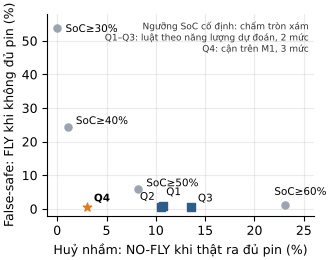

In [15]:
# Hình đánh đổi của lớp quyết định: đọc lại kết quả notebook 05 (không tính lại)
dq = pd.read_csv(ROOT / "reports" / "decision_results.csv", index_col=0)
fs = dq["False-safe (FLY khi không đủ pin)"] * 100
hn = dq["Huỷ nhầm (NO-FLY khi đủ pin)"] * 100
nhan_dq = {"Q0 SoC ≥ 30%": "SoC≥30%", "Q0 SoC ≥ 40%": "SoC≥40%", "Q0 SoC ≥ 50%": "SoC≥50%", "Q0 SoC ≥ 60%": "SoC≥60%",
           "Q1 B2 nhị phân": "Q1", "Q2 M1 nhị phân": "Q2", "Q3 Cận trên M1 nhị phân": "Q3", "Q4 Cận trên M1 3 mức": "Q4"}
lech = {"Q1": (2, 8), "Q2": (-15, 5), "Q3": (5, 4), "Q4": (5, 4), "SoC≥30%": (6, -3), "SoC≥40%": (6, 2),
        "SoC≥50%": (6, 2), "SoC≥60%": (-8, 7)}
fig, ax = plt.subplots(figsize=(3.5, 2.7))
for c in dq.index:
    nh = nhan_dq[c]
    mau_ = MAU["base"] if c.startswith("Q0") else (MAU["M1"] if c.startswith("Q4") else MAU["cmp"])
    ax.scatter(hn[c], fs[c], s=40 if nh == "Q4" else 26, color=mau_, zorder=3,
               marker="o" if c.startswith("Q0") else ("*" if nh == "Q4" else "s"))
    ax.annotate(nh, (hn[c], fs[c]), textcoords="offset points", xytext=lech[nh], fontsize=7.5,
                fontweight="bold" if nh == "Q4" else "normal")
ax.set_xlabel("Huỷ nhầm: NO-FLY khi thật ra đủ pin (%)")
ax.set_ylabel("False-safe: FLY khi không đủ pin (%)")
ax.set_xlim(-1, 26); ax.set_ylim(-2, 58)
ax.grid(alpha=0.25)
ax.text(25.5, 56, "Ngưỡng SoC cố định: chấm tròn xám\nQ1–Q3: luật theo năng lượng dự đoán, 2 mức\nQ4: cận trên M1, 3 mức",
        ha="right", va="top", fontsize=6.5, color="#333")
plt.tight_layout()
plt.savefig(FIGURES / "final_decision_tradeoff.png")
plt.show()

In [16]:
(ROOT / "reports" / "final_numbers.json").write_text(json.dumps(KQ, ensure_ascii=False, indent=1, default=float), encoding="utf-8")
print("Đã lưu reports/final_numbers.json")

Đã lưu reports/final_numbers.json
